# Reevaluación temporal con artefactos congelados

## Pregunta y relación con el objetivo

¿Mantiene el procedimiento seleccionado exclusivamente hasta 2022 su precisión al estimar promedios de 2023 y 2024 dados IPM y tasas de esos mismos años? Esta es reevaluación temporal, no prueba inédita: las ubicaciones históricas prom.pdf pp.13–14,18,22 y nueva ivestigacion .pdf pp.5–7 ya fueron verificadas en fase1. No se releen ni se usan sus métricas para buscar nuevos candidatos. La exposición previa limita fuerza confirmatoria aun con selección separada.

La reserva contiene 66 celdas, 33 por año, con los mismos filtros, Bogotá y peso uniforme. Las entradas de pobreza contemporáneas no garantizan anticipación antes de su publicación. Las predicciones describen una media departamental de registros elegibles, no personas individuales ni efectos de intervenciones.

## Método, supuestos y procedimiento

Se verifica cada huella de modelo y la tabla que sustentó su selección. Cada artefacto fue ajustado una sola vez sobre desarrollo 132 antes de errores reservados. Para ambos años se aplica predict al mismo objeto; nunca se actualiza con 2023 para evaluar 2024. Las escalas lineales persisten en el pipeline. Las métricas MAE, RMSE, sesgo y R² mantienen ecuaciones del notebook03 y protocolo §6. Se calculan por año y sobre las 66 filas concatenadas; esta última operación conserva igual peso de territorios y años.

Se comparan las referencias media y OLS con los ganadores por especificación mediante diferencias de MAE: $\Delta MAE=MAE_{modelo}-MAE_{referencia}$. Una diferencia positiva favorece la referencia. No se infiere significación estadística ni se escoge un nuevo ganador. Las diferencias ayudan a identificar si complejidad aporta precisión dentro de este transporte temporal, y los errores por territorio-año muestran heterogeneidad oculta por promedios.

Los supuestos de estabilidad de la relación pueden fallar por cambios de medición IPM, composición Saber o factores no incluidos. La evaluación no identifica esas causas. Si una referencia supera a modelos complejos, se informa directamente, sin volver a buscar parámetros. Una mala reevaluación no autoriza cambiar filtros, objetivo o búsqueda.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
root = Path.cwd()
if not (root / 'fase3').exists(): root = root.parent
sys.path.insert(0, str(root / 'fase3/fuentes'))
from comun import evaluate
reevaluacion = evaluate()

                        id  periodo       mae      rmse     sesgo        r2
                     media     2023 14.231429 17.087611 -3.473106 -0.043092
                     media     2024 15.576344 18.461869 -7.108168 -0.174039
                     media conjunto 14.903887 17.788017 -5.290637 -0.097048
                   ols_ipm     2023  8.667913 10.983039  0.043667  0.569072
                   ols_ipm     2024 10.436602 13.212595 -1.781540  0.398678
                   ols_ipm conjunto  9.552257 12.149070 -0.868937  0.488251
  gradient_boosting_ipm_02     2023  8.796859 10.646929  0.809592  0.595043
  gradient_boosting_ipm_02     2024 10.739447 13.316169 -0.652613  0.389213
  gradient_boosting_ipm_02 conjunto  9.768153 12.055652  0.078490  0.496091
                 ols_tasas     2023  6.488080  7.835041 -3.054205  0.780698
                 ols_tasas     2024  9.823690 11.309611 -7.334691  0.559418
                 ols_tasas conjunto  8.155885  9.728699 -5.194448  0.671844
gradient_boo

## Resultados reales, tablas y figura

La tabla anterior entrega errores en puntos para los modelos congelados, separados por año y concatenados. La siguiente celda interpreta esos valores sin alterar la selección y grafica el contraste temporal. La figura ubica el MAE del ganador y las referencias comunes; su variación anual es un diagnóstico descriptivo, no una prueba de cambio causal. Las diferencias exactas de todas las referencias y las 66 predicciones por artefacto están en CSV, sin redondeo de cálculo.

Ganador gradient_boosting_ambas_07, 2023: MAE 5.020614, RMSE 5.985372, sesgo -1.756802, R² 0.872020. ΔMAE frente a media -9.210814.
Referencias que superan al ganador en este conjunto: ninguna ; no se cambia la selección.
Ganador gradient_boosting_ambas_07, 2024: MAE 7.670549, RMSE 9.270673, sesgo -3.801227, R² 0.703958. ΔMAE frente a media -7.905796.
Referencias que superan al ganador en este conjunto: ninguna ; no se cambia la selección.
Ganador gradient_boosting_ambas_07, conjunto: MAE 6.345582, RMSE 7.802886, sesgo -2.779014, R² 0.788903. ΔMAE frente a media -8.558305.
Referencias que superan al ganador en este conjunto: ninguna ; no se cambia la selección.
Estas son reevaluaciones temporales actuales, no prueba inédita ni reproducción de métricas históricas. No hubo actualización con 2023, reselección ni interpretación causal.


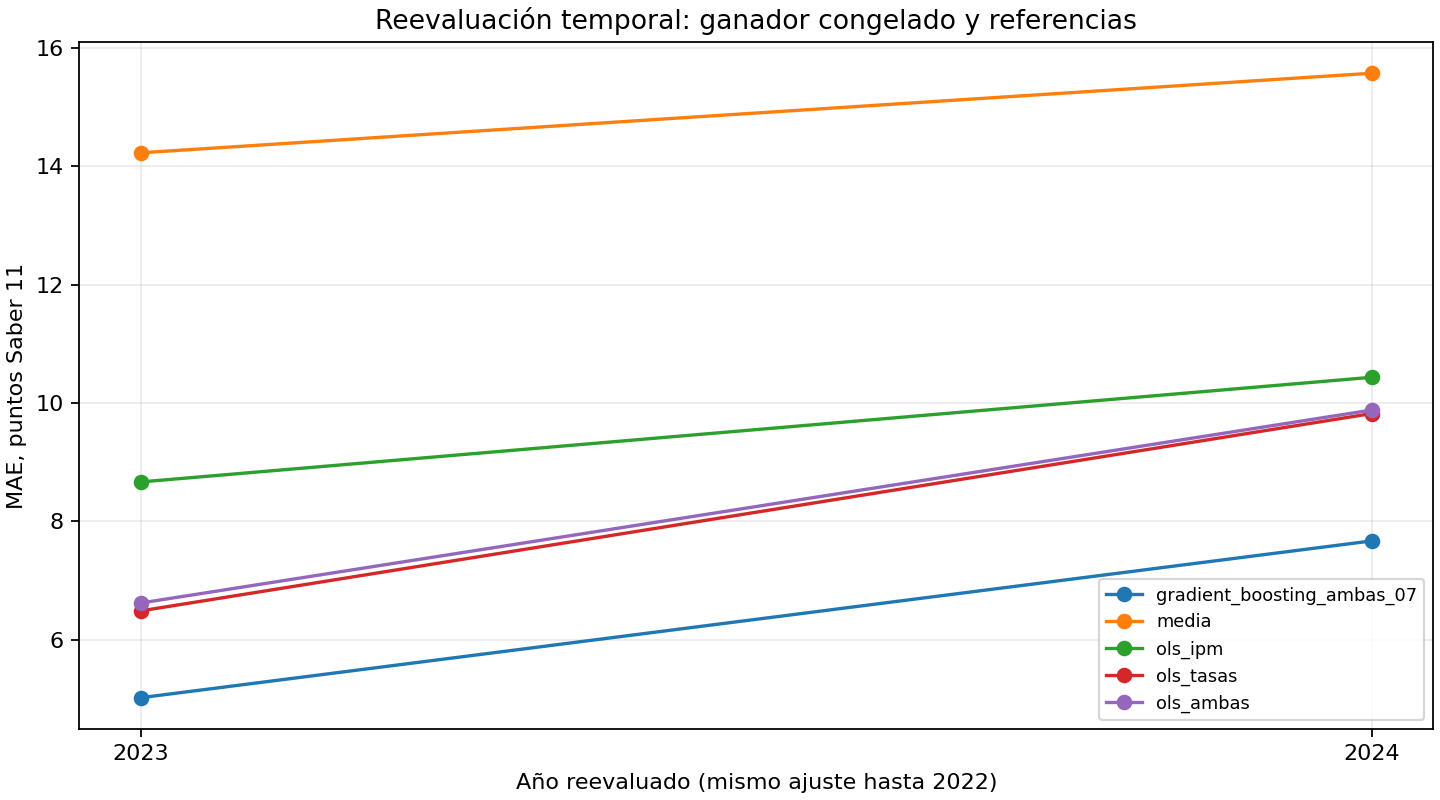

In [2]:
from informes import resumen_reevaluacion, figura
resumen_reevaluacion()
figura()
from IPython.display import Image, display
display(Image(filename=str(root / 'fase3/resultados/mae_temporal.png')))

## Discusión de la reevaluación actual

El ganador congelado obtuvo MAE 5.020614 en 2023 y 7.670549 en 2024; conjunto 6.345582, RMSE 7.802886, sesgo−2.779014 y R² 0.788903. Frente al desarrollo, el sesgo cambia de positivo a negativo, y dentro de reserva pasa de−1.756802 en 2023 a−3.801227 en 2024. La mayor subestimación y MAE de 2024 señalan menor estabilidad temporal; no identifican su causa. No se atribuyen automáticamente a cambios de pobreza, medición o composición.

Ninguna referencia supera al ganador global en estos conjuntos: la media alcanza MAE 14.903887 conjunto; OLS IPM9.552257, OLS tasas8.155885 y OLS ambas8.252112. Sin embargo, para la especificación IPM solo la referencia OLS sí mejora al Gradient Boosting seleccionado: MAE 9.552257 frente a9.768153 conjunto, con diferencias de+0.128946 en 2023 y+0.302844 en 2024 a favor de OLS. Este hallazgo indica que mayor complejidad no ayuda siempre, se reporta y no autoriza reselección. El ganador de tasas solas alcanza 6.436305 conjunto, próximo al ganador combinado; no se convierte esa proximidad en equivalencia demostrada.

La figura muestra la subida de MAE de 2023 a2024 en los objetos comparados. El CSV de predicciones permite examinar errores territorialmente; la gráfica anual no representa66 réplicas independientes ni un intervalo de incertidumbre. Todos los artefactos se aplicaron sin ajuste ni actualización y las predicciones permanecieron dentro de 0–500 sin recorte. Estos son resultados reales de esta reproducción; no prueban efectos causales ni sustituyen la advertencia de reserva previamente expuesta.

## Interpretación y límites de avance

Los valores y el comentario anterior proceden de la ejecución actual; ninguna conclusión se anticipó en función del ranking histórico. La precisión reservada no se usa para sustituir al ganador. El sesgo muestra dirección del error, mientras que R² compara contra la media observada del propio conjunto evaluado; la referencia de entrenamiento es distinta y puede obtener R² negativo. Por ello se leen conjuntamente MAE, RMSE, sesgo y R², sin reinterpretar un indicador aislado como efecto de pobreza.

Solo dos años reevaluados y territorios repetidos limitan generalización. Las advertencias de comparabilidad IPM, fuente global y enlace ecológico se conservan. El cierre entrega artefactos verificables y condición de avance a fase4 mediante autorización nueva; contraste territorial y simulación quedan pendientes. Véanse informe.md y verificacion.json para controles de predicciones, integridad histórica y reproducción de notebooks.